In [1]:
import pandas as pd

generation = pd.read_csv('/content/Plant_1_Generation_Data.csv')
weather = pd.read_csv('/content/Plant_1_Weather_Sensor_Data.csv')

print("GENERATION DATA")
display(generation.head())

print("Shape:", generation.shape)
print("\nColumns:", generation.columns.tolist())

print("\nWEATHER DATA")
display(weather.head())

print("Shape:", weather.shape)
print("\nColumns:", weather.columns.tolist())

GENERATION DATA


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,15-05-2020 00:00,4135001,1BY6WEcLGh8j5v7,0.0,0.0,0.0,6259559.0
1,15-05-2020 00:00,4135001,1IF53ai7Xc0U56Y,0.0,0.0,0.0,6183645.0
2,15-05-2020 00:00,4135001,3PZuoBAID5Wc2HD,0.0,0.0,0.0,6987759.0
3,15-05-2020 00:00,4135001,7JYdWkrLSPkdwr4,0.0,0.0,0.0,7602960.0
4,15-05-2020 00:00,4135001,McdE0feGgRqW7Ca,0.0,0.0,0.0,7158964.0


Shape: (68778, 7)

Columns: ['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD']

WEATHER DATA


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.184316,22.857507,0.0
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.084589,22.761668,0.0
2,2020-05-15 00:30:00,4135001,HmiyD2TTLFNqkNe,24.935753,22.592306,0.0
3,2020-05-15 00:45:00,4135001,HmiyD2TTLFNqkNe,24.846130,22.360852,0.0
4,2020-05-15 01:00:00,4135001,HmiyD2TTLFNqkNe,24.621525,22.165423,0.0


Shape: (3182, 6)

Columns: ['DATE_TIME', 'PLANT_ID', 'SOURCE_KEY', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']


In [2]:
print("GENERATION DATA")
print("Missing values:")
print(generation.isnull().sum())

print("\nDuplicate rows:", generation.duplicated().sum())

print("\nWEATHER DATA")
print("Missing values:")
print(weather.isnull().sum())

print("\nDuplicate rows:", weather.duplicated().sum())

GENERATION DATA
Missing values:
DATE_TIME      0
PLANT_ID       0
SOURCE_KEY     0
DC_POWER       0
AC_POWER       0
DAILY_YIELD    0
TOTAL_YIELD    0
dtype: int64

Duplicate rows: 0

WEATHER DATA
Missing values:
DATE_TIME              0
PLANT_ID               0
SOURCE_KEY             0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
dtype: int64

Duplicate rows: 0


In [3]:
# Convert timestamps into datetime format
generation['DATE_TIME'] = pd.to_datetime(
    generation['DATE_TIME'],
    format='%d-%m-%Y %H:%M'
)

weather['DATE_TIME'] = pd.to_datetime(
    weather['DATE_TIME']
)

print("Generation data time range:")
print(generation['DATE_TIME'].min(), "to",
      generation['DATE_TIME'].max())

print("\nWeather data time range:")
print(weather['DATE_TIME'].min(), "to",
      weather['DATE_TIME'].max())

print("\nUnique inverters:",
      generation['SOURCE_KEY'].nunique())

print("\nGeneration statistics:")
display(generation[['DC_POWER', 'AC_POWER', 'DAILY_YIELD']].describe())


Generation data time range:
2020-05-15 00:00:00 to 2020-06-17 23:45:00

Weather data time range:
2020-05-15 00:00:00 to 2020-06-17 23:45:00

Unique inverters: 22

Generation statistics:


,DC_POWER,AC_POWER,DAILY_YIELD
count,68778.000000,68778.000000,68778.000000
mean,3147.426211,307.802752,3295.968737
std,4036.457169,394.396439,3145.178309
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,429.000000,41.493750,2658.714286
75%,6366.964286,623.618750,6274.000000
max,14471.125000,1410.950000,9163.000000


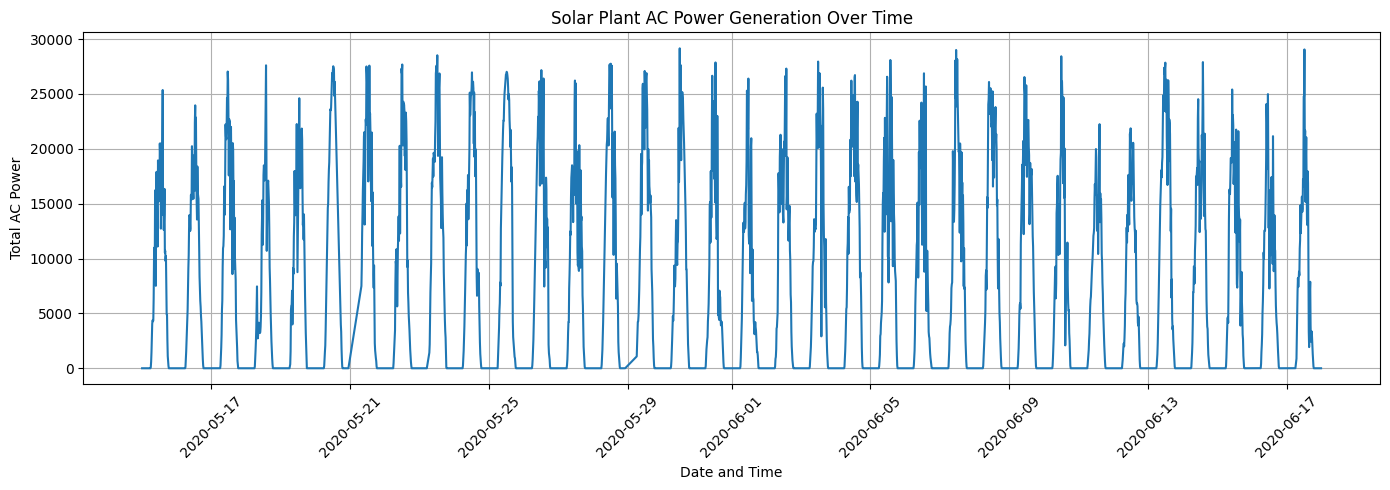

In [4]:
import matplotlib.pyplot as plt

# Total plant generation at each timestamp
plant_generation = (
    generation.groupby('DATE_TIME')['AC_POWER']
    .sum()
    .reset_index()
)

plt.figure(figsize=(14, 5))
plt.plot(
    plant_generation['DATE_TIME'],
    plant_generation['AC_POWER']
)

plt.title('Solar Plant AC Power Generation Over Time')
plt.xlabel('Date and Time')
plt.ylabel('Total AC Power')
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

Merged dataset shape: (3157, 5)

Correlation with AC power:


,AC_POWER
AC_POWER,1.000000
IRRADIATION,0.995864
MODULE_TEMPERATURE,0.961011
AMBIENT_TEMPERATURE,0.725879


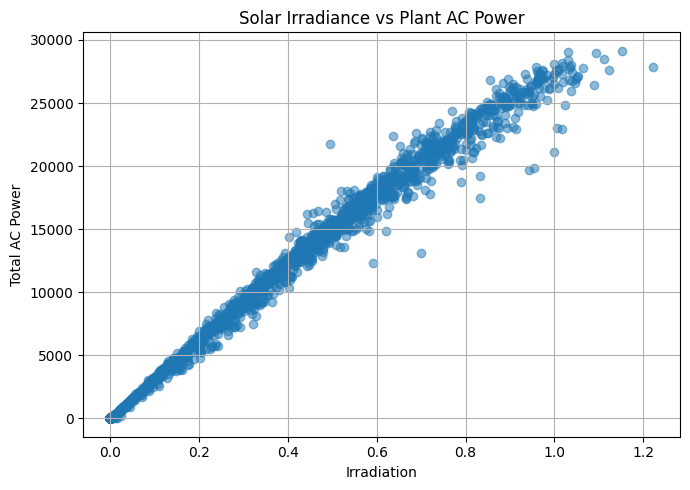

In [5]:
# Match plant generation with weather readings by timestamp
plant_generation = (
    generation.groupby('DATE_TIME', as_index=False)['AC_POWER']
    .sum()
)

weather_features = weather[
    ['DATE_TIME', 'AMBIENT_TEMPERATURE',
     'MODULE_TEMPERATURE', 'IRRADIATION']
]

merged_data = pd.merge(
    plant_generation,
    weather_features,
    on='DATE_TIME',
    how='inner'
)

print("Merged dataset shape:", merged_data.shape)

print("\nCorrelation with AC power:")
display(
    merged_data[
        ['AC_POWER', 'AMBIENT_TEMPERATURE',
         'MODULE_TEMPERATURE', 'IRRADIATION']
    ].corr()['AC_POWER'].sort_values(ascending=False)
)

plt.figure(figsize=(7, 5))
plt.scatter(
    merged_data['IRRADIATION'],
    merged_data['AC_POWER'],
    alpha=0.5
)
plt.title('Solar Irradiance vs Plant AC Power')
plt.xlabel('Irradiation')
plt.ylabel('Total AC Power')
plt.grid(True)
plt.tight_layout()
plt.show()

In [6]:
# Sort observations chronologically
merged_data = merged_data.sort_values('DATE_TIME').reset_index(drop=True)

# Create time-based features
merged_data['HOUR'] = merged_data['DATE_TIME'].dt.hour
merged_data['MINUTE'] = merged_data['DATE_TIME'].dt.minute

# Create a target for the next 15-minute interval
merged_data['TARGET_AC_POWER'] = merged_data['AC_POWER'].shift(-1)

# Remove the final row because its next reading is unavailable
forecast_data = merged_data.dropna().copy()

features = [
    'AC_POWER',
    'AMBIENT_TEMPERATURE',
    'MODULE_TEMPERATURE',
    'IRRADIATION',
    'HOUR',
    'MINUTE'
]

target = 'TARGET_AC_POWER'

print("Forecasting dataset shape:", forecast_data.shape)
print("\nInput features:", features)
print("Target:", target)

display(forecast_data[
    ['DATE_TIME'] + features + [target]
].head(10))


Forecasting dataset shape: (3156, 8)

Input features: ['AC_POWER', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION', 'HOUR', 'MINUTE']
Target: TARGET_AC_POWER


,DATE_TIME,AC_POWER,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,HOUR,MINUTE,TARGET_AC_POWER
0,2020-05-15 00:00:00,0.0,25.184316,22.857507,0.0,0,0,0.0
1,2020-05-15 00:15:00,0.0,25.084589,22.761668,0.0,0,15,0.0
2,2020-05-15 00:30:00,0.0,24.935753,22.592306,0.0,0,30,0.0
3,2020-05-15 00:45:00,0.0,24.846130,22.360852,0.0,0,45,0.0
4,2020-05-15 01:00:00,0.0,24.621525,22.165423,0.0,1,0,0.0
5,2020-05-15 01:15:00,0.0,24.536092,21.968571,0.0,1,15,0.0
6,2020-05-15 01:30:00,0.0,24.638674,22.352926,0.0,1,30,0.0
7,2020-05-15 01:45:00,0.0,24.873022,23.160919,0.0,1,45,0.0
8,2020-05-15 02:00:00,0.0,24.936930,23.026113,0.0,2,0,0.0
9,2020-05-15 02:15:00,0.0,25.012248,23.343229,0.0,2,15,0.0


In [8]:
from sklearn.model_selection import train_test_split

# Input features and target
X = forecast_data[features]
y = forecast_data[target]

# First 80% for training, last 20% for testing
split_index = int(len(forecast_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining period:")
print(forecast_data['DATE_TIME'].iloc[0],
      "to",
      forecast_data['DATE_TIME'].iloc[split_index - 1])

print("\nTesting period:")
print(forecast_data['DATE_TIME'].iloc[split_index],
      "to",
      forecast_data['DATE_TIME'].iloc[-1])


Training samples: 2524
Testing samples: 632

Training period:
2020-05-15 00:00:00 to 2020-06-11 09:00:00

Testing period:
2020-06-11 09:15:00 to 2020-06-17 23:30:00


In [9]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create and train the model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# Predict the test data
y_pred = model.predict(X_test)

# Evaluate the model
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Random Forest Forecasting Results")
print("---------------------------------")
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.4f}")

Random Forest Forecasting Results
---------------------------------
MAE:  1043.66
RMSE: 2102.42
R²:   0.9303


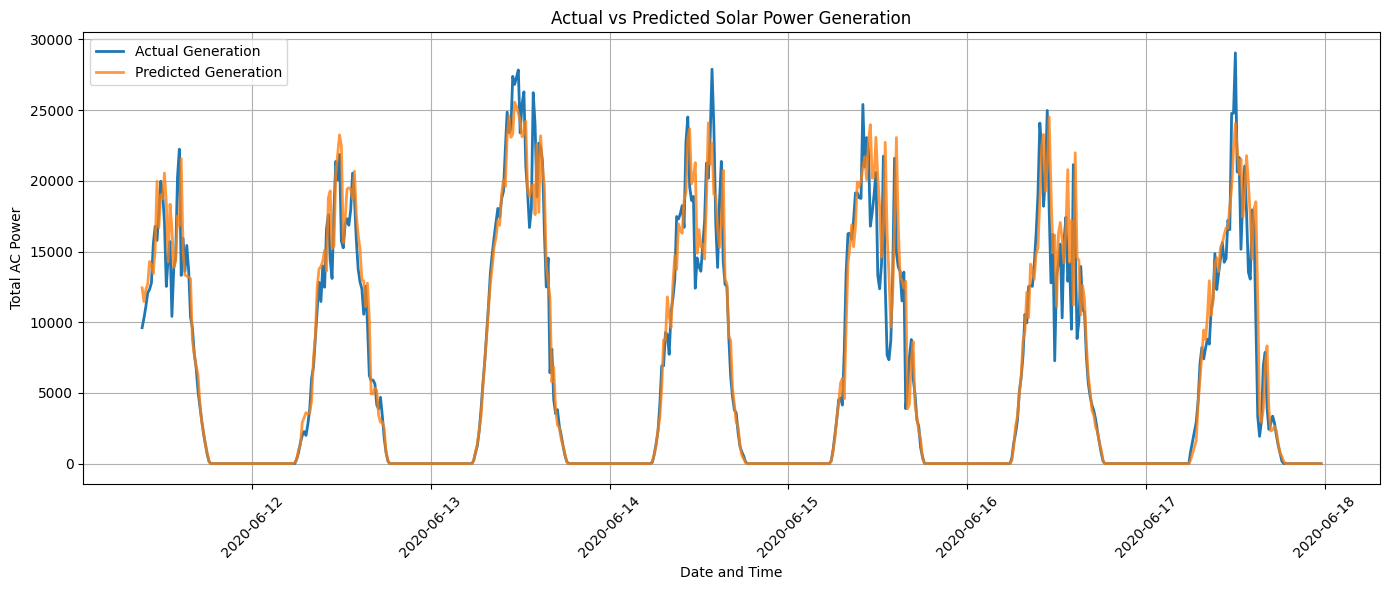

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    forecast_data['DATE_TIME'].iloc[split_index:],
    y_test.values,
    label='Actual Generation',
    linewidth=2
)

plt.plot(
    forecast_data['DATE_TIME'].iloc[split_index:],
    y_pred,
    label='Predicted Generation',
    linewidth=2,
    alpha=0.8
)

plt.title('Actual vs Predicted Solar Power Generation')
plt.xlabel('Date and Time')
plt.ylabel('Total AC Power')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [11]:
import joblib
import os

os.makedirs('/content/models', exist_ok=True)

joblib.dump(model, '/content/models/solar_forecast_model.pkl')

print("Model saved successfully!")
print("Location: /content/models/solar_forecast_model.pkl")


Model saved successfully!
Location: /content/models/solar_forecast_model.pkl
